# *Definición del problema* 

- *Dataset usado:* *[ImpactOfSocialMediaOnLife - Kaggle](https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life/data)*
- *Problema: Los estudiantes hoy en día usan mucho las redes sociales (yo incluido), mi intención con este proyecto es según el dataset escogido con 4500 registros y 16 columnas, poder predecir si un estudiante va a tener un impacto Negativo, Neutro o Beneficioso de su uso. El impacto se calcula en base a diferentes campos como: rendimiento académico (Academic_Performance_GPA) , calidad del sueño (Sleep_Quality_Score) y horas de este mismo (Sleep_Duration_Hours) además de media de horas diarias de uso (Daily_Usage_Hours), horas extra de uso en fin de semana (Weekend_Extra_Hours) e índice de salud mental (Mental_Health_Index)*  
- *Aplicación real: Herramienta de detección temprana para orientadores escolares, universidades o psicólogos que permita identificar a estudiantes en riesgo por abuso de redes sociales antes de que caigan sus notas o su salud mental.*
- *Tipo de problema: Clasificación multiclase.*
- *Variable Objetivo:* y = 'Overall_Impact'  

In [10]:
# Importacion de librerias 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

# Importacion de librerias de sklearn
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report, confusion_matrix

# Lectura inicial del archivo csv
df = pd.read_csv('Social_media_impact_on_life.csv')

print(f"Nulos: \n{df.isnull().sum()}")
df.describe()

Nulos: 
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64


,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


# *EDA (Análisis de datos exploratorio) Preguntas.*

1. *¿Son equilibrados nuestros datos, o están desbalanceados?*
2. *¿Los alumnos con peor tiempo y calidad de sueño, tienen un rendimiento académico peor?*
3. *¿Los alumnos con peor tiempo y calidad de sueño, tienen un mayor uso de redes sociales?*
4. *¿Tiene relación la edad, con las horas de uso de redes sociales?*
5. *¿Importa el tipo de red social que más usa cada alumno, o son todas igual de perjudiciales?*
6. *¿Tienen correlación la frecuencia con la que te comparas con los demás, con el nivel de estrés percibido?*
7. *Mapa de calor (Correlación de variables)*

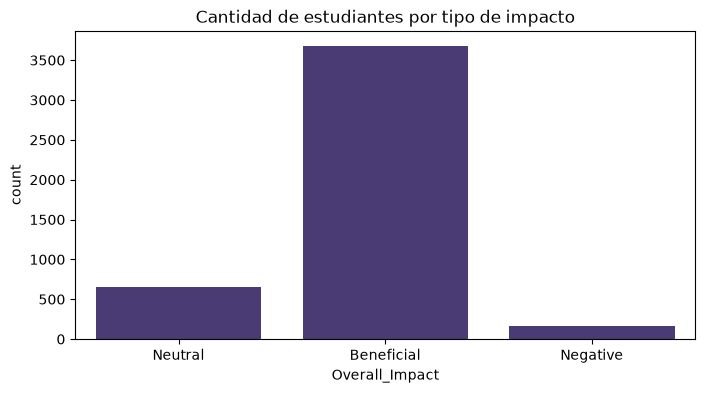

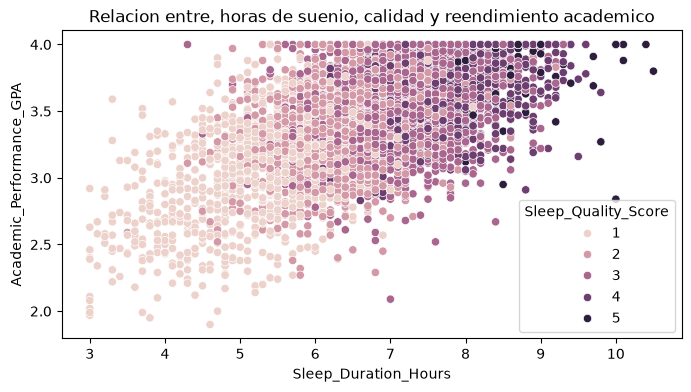

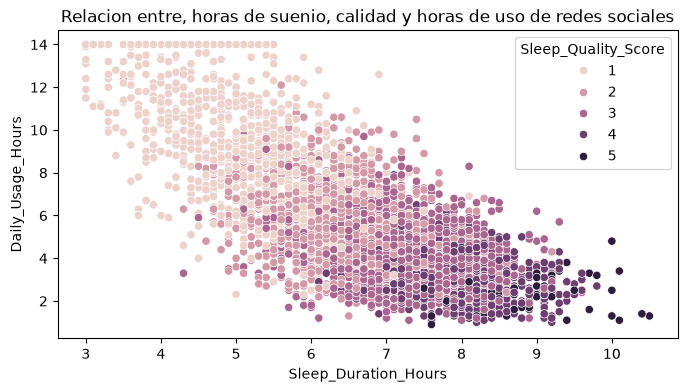

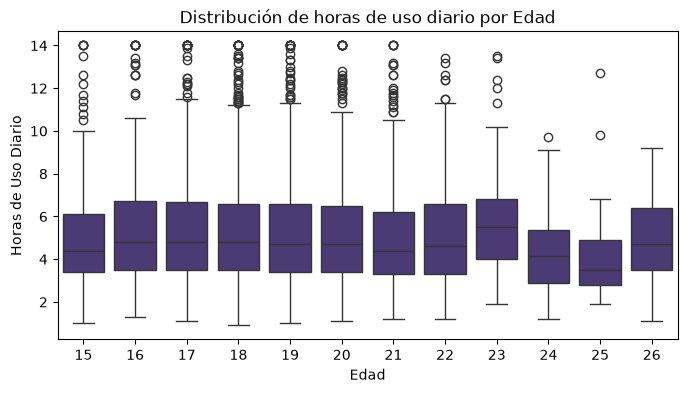

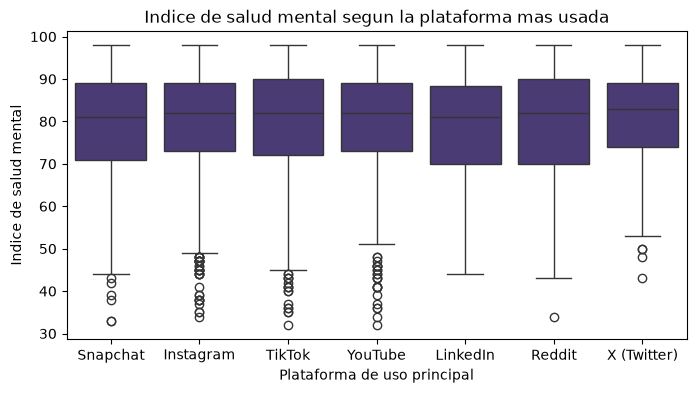

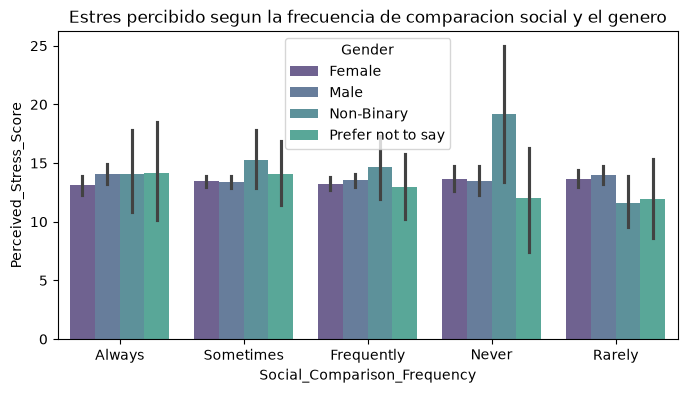

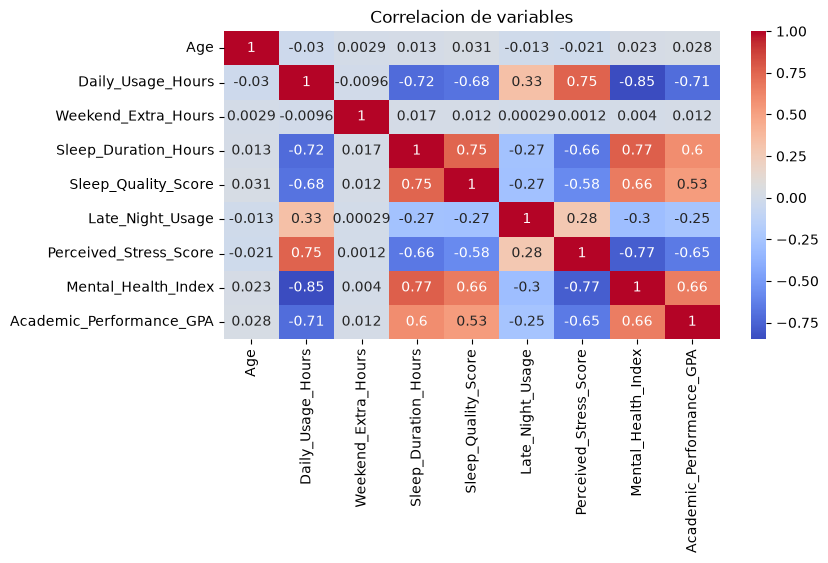

In [11]:
# Configuracion de paleta de colores de seaborn
sns.set_palette('viridis')

# 1. 
plt.figure(figsize=(8,4))
sns.countplot(df,x='Overall_Impact',)
plt.title('Cantidad de estudiantes por tipo de impacto')
plt.show()

# 2.
plt.figure(figsize=(8,4))
sns.scatterplot(df,x='Sleep_Duration_Hours', y='Academic_Performance_GPA', hue='Sleep_Quality_Score')
plt.title('Relacion entre, horas de suenio, calidad y reendimiento academico')
plt.show()

# 3.
plt.figure(figsize=(8,4))
sns.scatterplot(df,x='Sleep_Duration_Hours', y='Daily_Usage_Hours', hue='Sleep_Quality_Score')
plt.title('Relacion entre, horas de suenio, calidad y horas de uso de redes sociales')
plt.show()

# 4. 
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Age', y='Daily_Usage_Hours')
plt.title('Distribución de horas de uso diario por Edad')
plt.xlabel('Edad')
plt.ylabel('Horas de Uso Diario')
plt.show()

# 5.
plt.figure(figsize=(8,4))
sns.boxplot(df, x='Primary_Platform', y='Mental_Health_Index')
plt.title('Indice de salud mental segun la plataforma mas usada')
plt.xlabel('Plataforma de uso principal')
plt.ylabel('Indice de salud mental')
plt.show()

# 6.
plt.figure(figsize=(8,4))
sns.barplot(df, x='Social_Comparison_Frequency', y='Perceived_Stress_Score', hue='Gender', alpha=0.8)
plt.title('Estres percibido segun la frecuencia de comparacion social y el genero')
plt.show()

# 7.
plt.figure(figsize=(8,4))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', annot=True)
plt.title('Correlacion de variables')
plt.show()

# *EDA (Análisis de datos exploratorio) Respuestas.*

1. *Como podemos ver en el primer gráfico, hay muchísimos más estudiantes con un impacto beneficial que estudiantes con un impacto neutro o negativo, por lo cual nuestros datos están desbalanceados y puede perjudicar a nuestro modelo.*
2. *En el segundo gráfico, vemos como a medida que las horas de sueño y la calidad aumentan, progresivamente aumenta el índice GPA de cada alumno, aunque eso no quita que haya alumnos prodigio que con 3 horas de sueño y una calidad baja del mismo, tengan un índice GPA superior al resto de alumnos con mismas horas y calidad de sueño. Para el entrenamiento del modelo, se usará una variable que es el resultado de la multiplicación de horas de sueño x calidad de sueño.*
3. *Como vemos en el tercer gráfico, a medida que bajan las horas diarias de uso (sin contar horas extra en fin de semana) no solo aumentan las horas de sueño si no que aumenta la calidad del mismo.*
4. *En el cuarto gráfico, vemos que en el caso de los estudiantes, no tiene relación la edad con las horas diarias que usan las redes sociales.*
5. *Al ver el quinto gráfico, podemos ver dos cosas: la primera es que como tal , la mediana de índice de salud mental no varía según el tipo de red social que más usa el estudiante promedio, sin embargo, lo segundo que vemos es que redes sociales como Instagram/TikTok/Youtube, tienen una concentración de valores atípicos muy inferiores al resto, por lo que respecto a la pregunta si importa la red social principal, no, ya que no podemos tener en cuenta los valores atípicos de una categoría para dar una conclusión.*
6. *Viendo el sexto gráfico, a pesar de que pensaba que a más frecuencia de comparación social, mayor estrés, es incorrecto, no tienen ninguna relación ni tampoco con el sexo, lo único que podemos apreciar del gráfico, es que las personas de género no binario y quienes prefieren no decirlo, tienen unos outliers más altos por lo general.*
7. *Tras el análisis exploratorio, se ha decidido no eliminar ni transformar los valores atípicos detectados en variables como Mental_Health_Index, Daily_Usage_Hours o Sleep_Duration_Hours. Se verifica que no corresponden a errores de medición o de inserción en el DataFrame, sino a variaciones naturales de la conducta de los estudiantes. Dado que el objetivo principal es la detección temprana de alumnos con un impacto negativo (la clase minoritaria más desbalanceada), estos valores extremos representan perfiles críticos con alto nivel de riesgo psicológico o problemas graves de sueño. Eliminar o recortar estas observaciones provocaría una pérdida de información esencial para que los modelos puedan aprender a identificar estos casos.*

# *Aclaración de trata de valores nulos.* 
- *En el caso de este DataFrame, tenemos 46 valores nulos en Perceived_Stress_Score (~1%) y 85 en Academic_Performance_GPA (~1.8%). Es una proporción muy baja teniendo en cuenta que contamos con 4500 registros. En un primer momento planteé la opción de rellenar los valores nulos según el nivel académico, ya que el nivel de estrés percibido entre un alumno de High School (instituto) y uno de Postgraduate (máster) puede no ser el mismo. Sin embargo, teniendo en cuenta la pequeña proporción, el rendimiento del modelo no va a cambiar. Además, en el campo Academic_Performance_GPA esta agrupación no tiene relación directa, ya que es una variable que almacena el promedio de calificaciones de un alumno en una escala de 0 a 4; por lo cual, un alumno de secundaria puede tener un promedio igual o superior al de un alumno de grado (Undergraduate), aunque la complejidad de sus estudios no sea la misma.*

# *Flujo de trabajo / Workflow*
1.  *Feature engineering: Creación de variable Sleep_Score resultado de Sleep_Duration_Hours x Sleep_Quality_Score.*
2.  *Train/Test: Separación de los datos Train 80% / Test 20%.*
3.  *Sub-Pipelines: Creación de pipelines encargadas de: rellenado de nulos, mapeo de datos y normalización de estos.*
4.  *Main-Pipeline: Creación de ColumnTransformer encargado de la ejecución de sub-pipelines y creación de pipelines con los modelos.*
5.  *GridSearchCV: Uso de GridSearchCV para entrenar los modelos.*
6.  *Comparación de métricas y elección de modelo* 

In [12]:
# 1. 
df['Sleep_Score'] = df['Sleep_Duration_Hours'] * df['Sleep_Quality_Score']

# 2.
X = df.drop(columns=['Student_ID','Overall_Impact','Sleep_Duration_Hours','Sleep_Quality_Score'])
y = df['Overall_Impact']

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

X_train.head(10)

,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Sleep_Score
2347,19,Male,Undergraduate,Snapchat,4.3,2.4,Smartphone,False,Always,7.0,89,3.81,30.4
3827,17,Male,High School,TikTok,4.1,2.1,Smartphone,True,Sometimes,15.0,86,3.56,17.7
1606,17,Male,High School,Instagram,10.0,1.6,Smartphone,True,Sometimes,21.0,57,3.15,4.8
3808,20,Male,Undergraduate,TikTok,7.5,1.7,Laptop/PC,True,Always,18.0,69,2.89,5.4
2565,17,Male,High School,TikTok,3.5,2.0,Smartphone,True,Frequently,6.0,82,3.64,24.0
4137,19,Male,Undergraduate,TikTok,6.1,1.2,Smartphone,True,Always,11.0,84,3.74,20.1
689,18,Male,Undergraduate,YouTube,5.0,2.3,Smartphone,True,Frequently,7.0,81,3.42,5.6
2052,18,Female,Undergraduate,Instagram,3.9,2.2,Smartphone,False,Sometimes,12.0,79,3.25,21.6
1749,18,Male,Undergraduate,YouTube,4.6,3.0,Smartphone,True,Frequently,17.0,83,3.30,21.0
729,18,Non-Binary,Undergraduate,Snapchat,5.1,0.9,Smartphone,True,Always,18.0,87,3.35,21.6


In [ ]:
# 3. 
# Separacion por tipo de columnas.
num_cols = ['Age','Daily_Usage_Hours','Weekend_Extra_Hours','Perceived_Stress_Score','Sleep_Score','Mental_Health_Index','Academic_Performance_GPA']
cat_ord_cols = ['Academic_Level','Social_Comparison_Frequency']
cat_nom_cols = ['Gender','Device_Type','Primary_Platform','Late_Night_Usage']

# Ordenes de columnas ordinales.
academic_level_order = ['High School', 'Undergraduate', 'Postgraduate']
social_comparison_frequency_order = ['Never', 'Rarely', 'Sometimes', 'Frequently', 'Always']

# Sub-Pipeline para la imputacion de valores nulos con la mediana y normalizar estos datos.
pipe_num_transformer = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# Sub-Pipeline para mapear columnas ordinales y normalizar estos datos.
pipe_ord_transformer = Pipeline([
    ('ordinal', OrdinalEncoder(categories=[academic_level_order,social_comparison_frequency_order])),
    ('scaler', MinMaxScaler())
])

# Sub-Pipeline para mapear columnas nominales.
nom_transformer = OneHotEncoder(drop='first', handle_unknown='ignore')

# 4.
# Pipeline principal que engloba los sub-pipelines.
preprocesor = ColumnTransformer(transformers=[
    ('num', pipe_num_transformer, num_cols),
    ('ord', pipe_ord_transformer, cat_ord_cols),
    ('nom', nom_transformer, cat_nom_cols)
])

# 5.
# Definicion de diccionarios de parametros para GridSearchCV.
param_grid_rf = { # Diccionario RandomForest,
    'classifier__n_estimators': [50,100,150,200,250],
    'classifier__max_depth': [None,10]
}

param_grid_log = { # Diccionario LogisticRegression.
    'classifier__C': [0.1,1,10]
}

# Pipeline que transforma los datos y define el modelo.
pipe_rf = Pipeline([ # Pipeline RandomForest.
    ('preprocesor', preprocesor),
    ('classifier', RandomForestClassifier(class_weight='balanced',random_state=42))
])

pipe_log = Pipeline([ # Pipeline LogisticRegression.
    ('preprocesor', preprocesor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# Definicion de GridSearchCV para cada modelo.
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
grid_log = GridSearchCV(pipe_log, param_grid_log, cv=5, scoring='f1_macro', n_jobs=-1)

# Entrenamiento.
grid_rf.fit(X_train,y_train)
grid_log.fit(X_train,y_train)

# 6.
# Comparacion de metricas.
print(f"F1 - RandomForest: {grid_rf.best_score_}")
print(f"F1 - LogisticRegression: {grid_log.best_score_}")

F1 - RandomForest: 0.8403695792730433
F1 - LogisticRegression: 0.8358042807777073


In [14]:
best_rf = grid_rf.best_estimator_
best_log = grid_log.best_estimator_

y_pred_rf = best_rf.predict(X_test)
y_pred_log = best_log.predict(X_test)

print("--- RandomForest Classification Report ---")
print(classification_report(y_test,y_pred_rf))

print("--- LogisticRegression Classification Report ---")
print(classification_report(y_test,y_pred_log))


print("--- RandomForest ConfusionMatrix ---")
print(confusion_matrix(y_test,y_pred_rf))

print("--- LogisticRegression ConfusionMatrix ---")
print(confusion_matrix(y_test,y_pred_log))

--- RandomForest Classification Report ---
              precision    recall  f1-score   support

  Beneficial       0.97      0.95      0.96       736
    Negative       0.77      0.73      0.75        33
     Neutral       0.68      0.79      0.73       131

    accuracy                           0.91       900
   macro avg       0.81      0.82      0.81       900
weighted avg       0.92      0.91      0.92       900

--- LogisticRegression Classification Report ---
              precision    recall  f1-score   support

  Beneficial       0.98      0.93      0.96       736
    Negative       0.76      0.88      0.82        33
     Neutral       0.67      0.82      0.74       131

    accuracy                           0.91       900
   macro avg       0.80      0.88      0.84       900
weighted avg       0.93      0.91      0.92       900

--- RandomForest ConfusionMatrix ---
[[696   0  40]
 [  0  24   9]
 [ 21   7 103]]
--- LogisticRegression ConfusionMatrix ---
[[686   0  50]
 [  0

# *Comparación de métricas y elección de modelo*

-   *Lo primero que se ve al mirar los resultados, es que los datos están desbalanceados, hay 736 casos Beneficial, 33 Negative y 131 Neutral, por lo cual, el accuracy de los modelos puede estar inflado.*
-   *Después de comprobar los dos modelos, tanto el de regresión logística como el random forest, el modelo de regresión logística ha tenido un mejor resultado.*
    *Sin embargo, menos en los casos Negative, tienen un f1-score muy parecido, con respecto a la comparación primera que hice sin usar CrossValidation veo que todas las métricas han bajado, lo que demuestra que efectivamente los datos están desbalanceados y no son suficientes para que el modelo tenga un mejor funcionamiento.*
-   *Como propuesta de mejora, lo mejor sería trabajar el modelo con unos datos más balanceados (mayor número de casos Negative y Neutral) además de un mayor número de registros en el dataset.*
-   *Al ser un problema de clasificación multiclase se optó por comparar estos dos modelos (RandomForest / LogisticRegression) y tras comparar sus métricas, como mejor modelo elijo al modelo de regresión logística ya que ha conseguido una mejor puntuación en los casos Negative con un 82% frente al 75% del random forest.*
    *El objetivo principal es detectar casos Negative para su tratamiento temprano, con lo cual los casos Beneficial y Neutral tienen a mi parecer menos peso con respecto a Negative, por lo cual si escogiéramos el modelo RandomForest, le estaríamos quitando importancia al objetivo principal del proyecto.*